# Customer Churn Prediction

## 1. Project Overview

The Customer Churn Prediction project uses Machine Learning to predict whether a customer is likely to leave a company.

The project uses the Telco Customer Churn dataset, which contains customer information such as tenure, contract type, internet service, monthly charges, and total charges.

## 2. Project Objective

The main objective is to identify customers who may leave the company so that the business can take steps to improve customer retention.

## 3. Technology Used

- Python
- Pandas and NumPy
- Scikit-learn
- Logistic Regression
- Jupyter Notebook
- Flask
- HTML and CSS

In [1]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [3]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check the Churn column
print("\nChurn counts:")
print(df["Churn"].value_counts())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
churn_counts = df["Churn"].value_counts()

churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print("Customer counts:")
print(churn_counts)

print("\nCustomer percentages:")
print(churn_percentage.round(2))

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [5]:
# Check for blank strings in TotalCharges
blank_charges = df["TotalCharges"].str.strip().eq("").sum()

print("Blank TotalCharges values:", blank_charges)

# Display the affected rows
print(df.loc[df["TotalCharges"].str.strip().eq(""),
             ["customerID", "tenure", "TotalCharges"]])

Blank TotalCharges values: 11
      customerID  tenure TotalCharges
488   4472-LVYGI       0             
753   3115-CZMZD       0             
936   5709-LVOEQ       0             
1082  4367-NUYAO       0             
1340  1371-DWPAZ       0             
3331  7644-OMVMY       0             
3826  3213-VVOLG       0             
4380  2520-SGTTA       0             
5218  2923-ARZLG       0             
6670  4075-WKNIU       0             
6754  2775-SEFEE       0             


In [6]:
import pandas as pd

# Convert blank strings to missing values
df["TotalCharges"] = df["TotalCharges"].str.strip()
df["TotalCharges"] = df["TotalCharges"].replace("", pd.NA)

# Convert the column to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check the result
print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing TotalCharges values:", df["TotalCharges"].isnull().sum())

df.loc[df["TotalCharges"].isnull(),
       ["customerID", "tenure", "TotalCharges"]]

TotalCharges data type: float64
Missing TotalCharges values: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [7]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:",
      df["TotalCharges"].isnull().sum())

print("TotalCharges data type:",
      df["TotalCharges"].dtype)

Missing values after cleaning: 0
TotalCharges data type: float64


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Customer Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


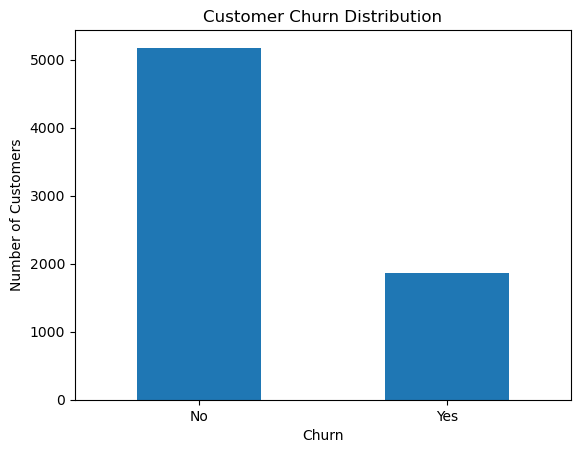

In [9]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

print("Customer Churn Counts:")
print(churn_counts)

print("\nCustomer Churn Percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


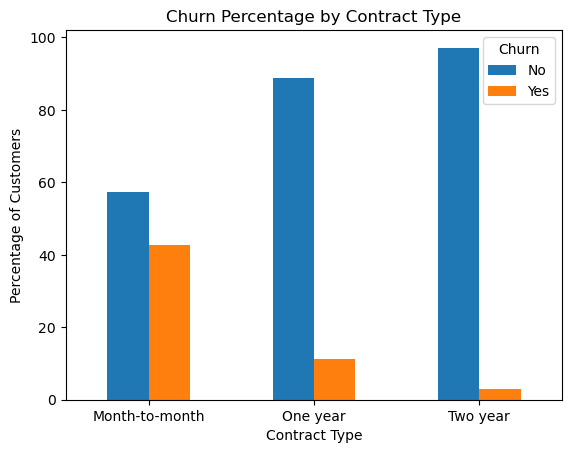

In [10]:
churn_by_contract = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_contract.round(2))

churn_by_contract.plot(kind="bar")

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

In [11]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 36, float("inf")],
    labels=["New (0-12 months)",
            "Medium (13-36 months)",
            "Long-term (37+ months)"]
)

churn_by_tenure = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_tenure.round(2))

Churn                      No    Yes
TenureGroup                         
New (0-12 months)       52.56  47.44
Medium (13-36 months)   74.46  25.54
Long-term (37+ months)  88.07  11.93


In [12]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
).round(2)

,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


In [13]:
churn_by_internet = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_internet.round(2))


Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


In [14]:
churn_by_support = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print(churn_by_support.round(2))


Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


In [15]:
# Separate features and target
X = df.drop(columns=["Churn", "customerID", "TenureGroup"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [16]:
# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical columns:")
print(categorical_cols)

print("\nNumber of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical columns: 4
Number of categorical columns: 15


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (5634, 19)
Testing features: (1409, 19)

Training churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing churn distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Process numerical columns
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

print("Customer Churn Model trained successfully!")

Customer Churn Model trained successfully!


In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict churn for test customers
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 80.55 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Confusion Matrix:
[[926 109]
 [165 209]]


In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Get churn probabilities for the test data
churn_probabilities = model.predict_proba(X_test)[:, 1]

# Use a 0.40 threshold instead of the default 0.50
y_pred_40 = (churn_probabilities >= 0.40).astype(int)

print("Accuracy at 0.40 threshold:",
      round(accuracy_score(y_test, y_pred_40) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_40))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_40))

Accuracy at 0.40 threshold: 77.71 %

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409


Confusion Matrix:
[[845 190]
 [124 250]]


In [22]:
print("Testing notebook output")

Testing notebook output


In [31]:
from sklearn.metrics import accuracy_score, recall_score, precision_score

churn_probabilities = model.predict_proba(X_test)[:, 1]

for threshold in [0.30, 0.40, 0.50, 0.60]:
    y_pred_threshold = (churn_probabilities >= threshold).astype(int)

    accuracy = accuracy_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    precision = precision_score(y_test, y_pred_threshold)

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Accuracy:  {accuracy * 100:.2f}%")
    print(f"Recall:    {recall * 100:.2f}%")
    print(f"Precision: {precision * 100:.2f}%")


Threshold: 0.30
Accuracy:  74.95%
Recall:    75.40%
Precision: 51.93%

Threshold: 0.40
Accuracy:  77.71%
Recall:    66.84%
Precision: 56.82%

Threshold: 0.50
Accuracy:  80.55%
Recall:    55.88%
Precision: 65.72%

Threshold: 0.60
Accuracy:  79.91%
Recall:    40.11%
Precision: 71.77%


### Classification Threshold Comparison

I evaluated the Logistic Regression churn model at thresholds of 0.30, 0.40, 0.50, and 0.60.

The default threshold of 0.50 achieved the highest accuracy of 80.55%. The threshold of 0.30 achieved the highest churn recall of 75.40%, while the threshold of 0.60 achieved the highest churn precision of 71.77%.

This comparison demonstrates the trade-off between accuracy, recall, and precision. The final threshold should be selected according to the business objective and the cost of incorrect predictions.

## Model Evaluation Summary

The Logistic Regression model achieved 80.55% accuracy at the default classification threshold of 0.50.

The confusion matrix showed that the model correctly identified 209 customers who churned and 926 customers who stayed.

The model's churn recall was 55.88%, meaning it identified approximately 56% of the customers who actually churned.

The threshold experiments showed that lowering the threshold increased recall but reduced accuracy and precision. The threshold should be selected according to the company's customer-retention goals.

## Flask Web Application

I developed a web application using Flask to make the Customer Churn Prediction model accessible through a user-friendly interface.

### How the Application Works

1. The user enters customer details into an HTML form.
2. Flask receives the submitted information.
3. The customer data is converted into a Pandas DataFrame.
4. The saved Machine Learning pipeline generates a churn prediction and probability.
5. The application displays the predicted outcome and risk level on the website.

### Project Outcome

The application connects a trained Logistic Regression model with a Flask web interface, allowing users to test customer details and view churn predictions.

In [23]:
print("Model classes:", model.classes_)

Model classes: [0 1]


In [24]:
# Create a class-weighted model
weighted_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the model
weighted_model.fit(X_train, y_train)

# Predict test results
weighted_pred = weighted_model.predict(X_test)

# Evaluate
print("Weighted Model Accuracy:",
      round(accuracy_score(y_test, weighted_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, weighted_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, weighted_pred))

Weighted Model Accuracy: 73.81 %

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Confusion Matrix:
[[747 288]
 [ 81 293]]


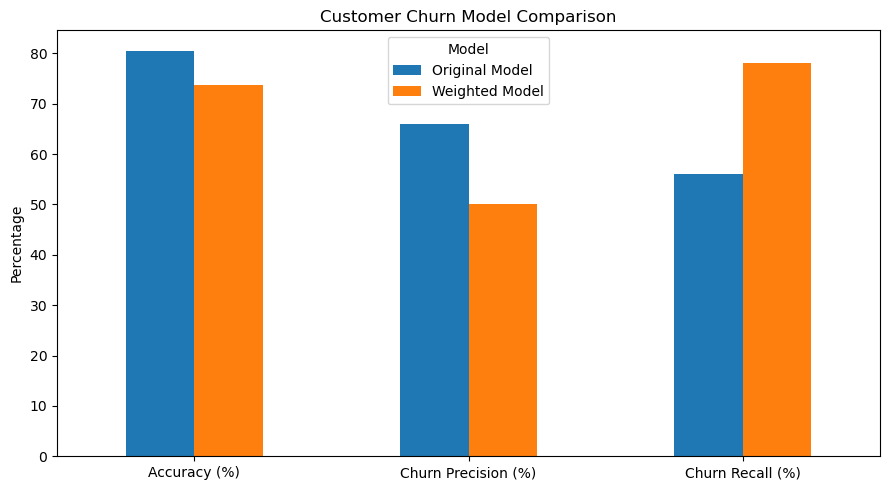

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Original Model": [80.55, 66, 56],
    "Weighted Model": [73.81, 50, 78]
}, index=["Accuracy (%)", "Churn Precision (%)",
          "Churn Recall (%)"])

comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Customer Churn Model Comparison")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import roc_auc_score

# Get churn probabilities from both models
original_prob = model.predict_proba(X_test)[:, 1]
weighted_prob = weighted_model.predict_proba(X_test)[:, 1]

print("Original Model ROC-AUC:",
      round(roc_auc_score(y_test, original_prob), 3))

print("Weighted Model ROC-AUC:",
      round(roc_auc_score(y_test, weighted_prob), 3))

Original Model ROC-AUC: 0.842
Weighted Model ROC-AUC: 0.842


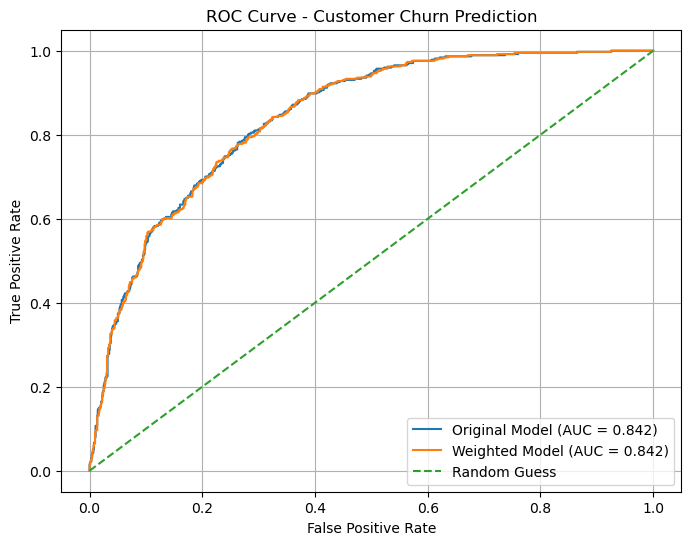

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curves
fpr_original, tpr_original, _ = roc_curve(
    y_test, original_prob
)

fpr_weighted, tpr_weighted, _ = roc_curve(
    y_test, weighted_prob
)

# Calculate AUC scores
auc_original = roc_auc_score(y_test, original_prob)
auc_weighted = roc_auc_score(y_test, weighted_prob)

# Plot curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_original, tpr_original,
    label=f"Original Model (AUC = {auc_original:.3f})"
)

plt.plot(
    fpr_weighted, tpr_weighted,
    label=f"Weighted Model (AUC = {auc_weighted:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
import joblib

joblib.dump(weighted_model, "customer_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [29]:
import joblib

# Load the saved model
loaded_model = joblib.load("customer_churn_model.pkl")

# Predict churn for a few test customers
sample_predictions = loaded_model.predict(X_test.head(5))

print("Predictions:", sample_predictions)
print("Actual values:", y_test.head(5).to_list())

Predictions: [0 1 0 1 0]
Actual values: [0, 0, 0, 0, 0]


In [30]:
print("Model classes:", model.classes_)
print("Default classification threshold: 0.50")

Model classes: [0 1]
Default classification threshold: 0.50
